<a href="https://colab.research.google.com/github/AnkaRezaa/machine_learning_254107023002/blob/main/JS06-regresi/Tugas_Praktikum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Identifikasi Variabel & Penjelasan DatasetDataset insurance.csv memuat informasi demografis dan gaya hidup nasabah untuk memprediksi besarnya tagihan biaya medis personal.Variabel Bebas (Fitur / $X$):age: Usia nasabah (numerik).sex: Jenis kelamin (female / male, kategorikal).bmi: Body Mass Index / Indeks Massa Tubuh (numerik).children: Jumlah anak/tanggungan yang ditanggung asuransi (numerik).smoker: Status merokok (yes / no, kategorikal).region: Wilayah tempat tinggal (northeast, southeast, southwest, northwest, kategorikal).Variabel Target ($y$):charges: Biaya medis personal yang ditagihkan (numerik kontinu). Variabel Target ($y$):charges: Biaya medis personal yang ditagihkan (numerik kontinu).

Implementasi Kode Python Complete

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# ---------------------------------------------------------
# Step 1: Load Data & Preprocessing (Encoding)
# ---------------------------------------------------------
df = pd.read_csv('/content/insurance.csv')

# Encoding variabel kategorikal (sex, smoker, region) menjadi numerik
df_encoded = pd.get_dummies(df, columns=['sex', 'smoker', 'region'], drop_first=True)

# Memisahkan Fitur (X) dan Target (y)
X = df_encoded.drop('charges', axis=1)
y = df_encoded['charges']

# ---------------------------------------------------------
# Step 2: Pembagian Dataset (80% Train, 20% Test)
# ---------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ---------------------------------------------------------
# Step 3: Feature Scaling
# ---------------------------------------------------------
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ---------------------------------------------------------
# Step 4 & 5: Pemodelan & Pelatihan (Multiple Linear Regression)
# ---------------------------------------------------------
model = LinearRegression()
model.fit(X_train_scaled, y_train)

# Prediksi pada data uji
y_pred = model.predict(X_test_scaled)

# ---------------------------------------------------------
# Step 6: Evaluasi Model
# ---------------------------------------------------------
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("=== HASIL EVALUASI MULTIPLE LINEAR REGRESSION ===")
print(f"Mean Absolute Error (MAE)     : {mae:.2f}")
print(f"Mean Squared Error (MSE)      : {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared (R2 Score)          : {r2:.4f}")

=== HASIL EVALUASI MULTIPLE LINEAR REGRESSION ===
Mean Absolute Error (MAE)     : 4181.19
Mean Squared Error (MSE)      : 33596915.85
Root Mean Squared Error (RMSE): 5796.28
R-squared (R2 Score)          : 0.7836


Kode Visualisasi Data

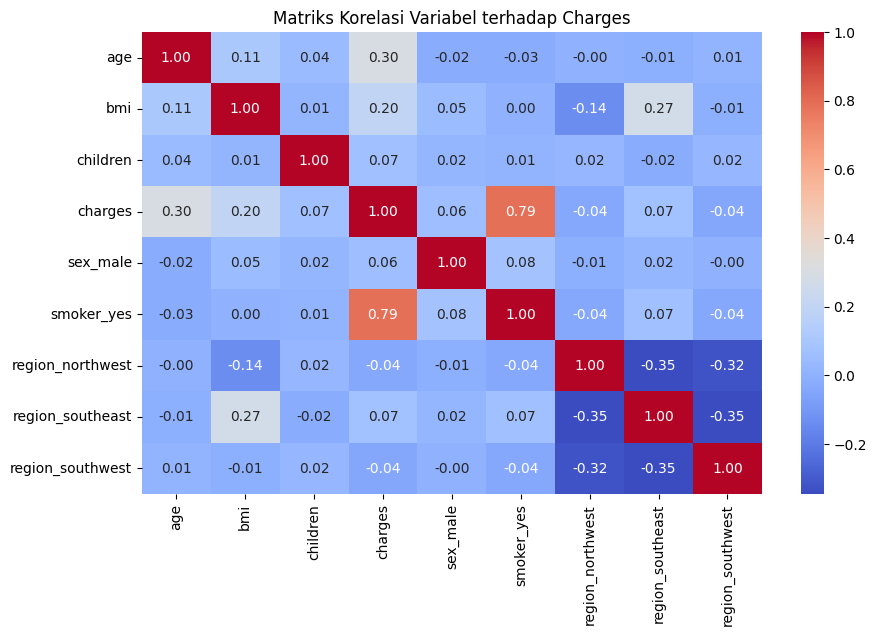

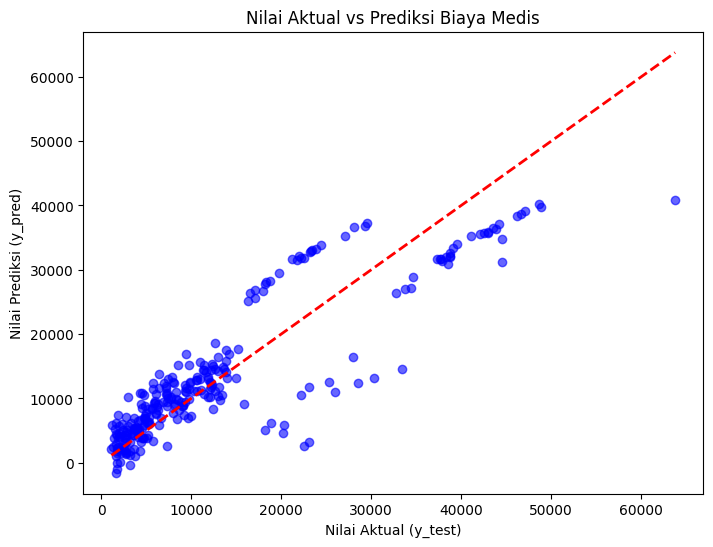

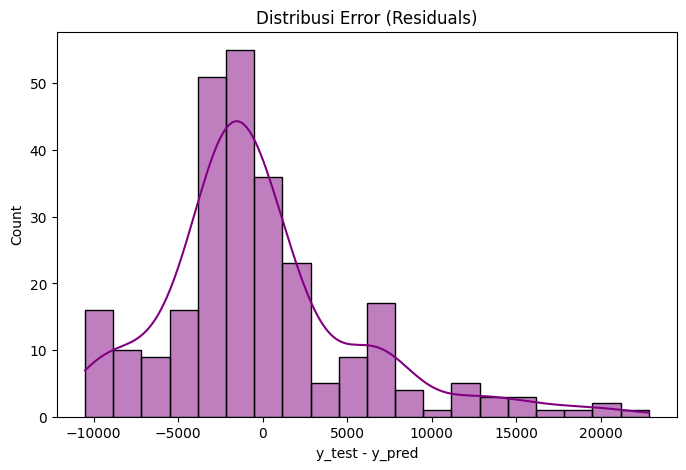

In [3]:
# Visualisasi 1: Heatmap Korelasi
plt.figure(figsize=(10, 6))
sns.heatmap(df_encoded.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriks Korelasi Variabel terhadap Charges')
plt.show()

# Visualisasi 2: Actual vs Predicted Charges
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Nilai Aktual (y_test)')
plt.ylabel('Nilai Prediksi (y_pred)')
plt.title('Nilai Aktual vs Prediksi Biaya Medis')
plt.show()

# Visualisasi 3: Residual Distribution Plot
residuals = y_test - y_pred
plt.figure(figsize=(8, 5))
sns.histplot(residuals, kde=True, color='purple', bins=20)
plt.title('Distribusi Error (Residuals)')
plt.xlabel('y_test - y_pred')
plt.show()

Analisis Hasil

Pengaruh Fitur: Variabel smoker_yes (status merokok) memiliki pengaruh paling dominan terhadap lonjakan charges, diikuti oleh variabel age dan bmi.Performa Model: Nilai $R^2 \approx 0.783$ menunjukkan bahwa kombinasi seluruh fitur pada model Multiple Linear Regression mampu menjelaskan sekitar 78.3% variansi dari biaya medis personal.